<a href="https://colab.research.google.com/github/itharavenikarthik/Deep-Learning/blob/main/DL_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import glob
import os

# Search for the diabetes.csv file in the current directory and subdirectories
search_results = glob.glob('**/diabetes.csv', recursive=True)

if search_results:
    file_path = search_results[0]
    print(f"Found file at: {file_path}")
    dataset = pd.read_csv(file_path)
    display(dataset.head(10))
else:
    print("Could not find 'diabetes.csv' automatically. Please verify the file path or upload the file to your environment.")

Could not find 'diabetes.csv' automatically. Please verify the file path or upload the file to your environment.


In [ ]:
import pandas as pd

# URL to the standard Pima Indians Diabetes dataset
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'

# Define the column names as this raw file doesn't have a header
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

# Load the dataset
dataset = pd.read_csv(url, names=column_names)
print("Successfully loaded the Pima Indians Diabetes Dataset!")

# Display the first 10 rows
display(dataset.head(10))

Successfully loaded the Pima Indians Diabetes Dataset!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


### Convolutional Neural Network (1D CNN) for Tabular Diabetes Data
Because our dataset is tabular, we can use 1D convolutions (`Conv1D`) by treating each feature as a distinct sequence element or signal. We will scale the data, reshape it to `(samples, features, 1)`, and build a simple neural network in Keras.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

# 1. Prepare Features (X) and Target (y)
X = dataset.drop('Outcome', axis=1).values
y = dataset['Outcome'].values

# 2. Split dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Reshape data for Conv1D: (samples, features, channels)
# Here, we have 8 features, which we treat as 8 steps of a 1-channel signal
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print(f"Reshaped X_train shape: {X_train_cnn.shape}")
print(f"Reshaped X_test shape: {X_test_cnn.shape}")

Reshaped X_train shape: (614, 8, 1)
Reshaped X_test shape: (154, 8, 1)


In [ ]:
# 5. Build the Conv1D Neural Network
model = Sequential([
    Conv1D(filters=32, kernel_size=2, activation='relu', input_shape=(X_train_cnn.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),

    Flatten(),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 7, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,233 (12.63 KB)

 Trainable params: 3,233 (12.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 6. Train the model
history = model.fit(
    X_train_cnn, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# 7. Evaluate on test data
loss, accuracy = model.evaluate(X_test_cnn, y_test, verbose=0)
print(f"\nTest Accuracy: {accuracy:.4f}")
print(f"Test Loss: {loss:.4f}")

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6649 - loss: 0.6554 - val_accuracy: 0.7419 - val_loss: 0.5959
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7101 - loss: 0.6111 - val_accuracy: 0.7419 - val_loss: 0.5420
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7536 - loss: 0.5609 - val_accuracy: 0.7581 - val_loss: 0.5079
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7754 - loss: 0.5408 - val_accuracy: 0.7742 - val_loss: 0.4809
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7699 - loss: 0.5228 - val_accuracy: 0.7742 - val_loss: 0.4717
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7663 - loss: 0.5182 - val_accuracy: 0.7581 - val_loss: 0.4637
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7681 - loss: 0.4980 - val_accuracy: 0.7581 - val_loss: 0.4671
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7736 - loss: 0.4897 - val_accuracy: 0.7581 - 

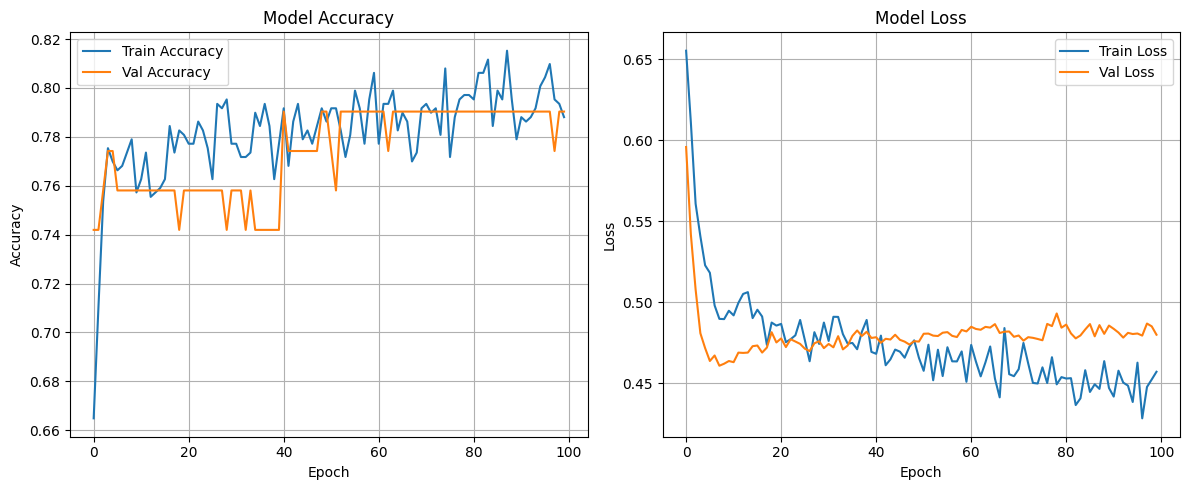

In [ ]:
# 8. Plot training & validation accuracy and loss values
plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### How does a CNN work on Tabular Data instead of Images?

Typically, we associate Convolutional Neural Networks (CNNs) with **2D images** where a filter moves horizontally and vertically across pixels to capture spatial features (like edges, shapes, and textures).

However, a **1D CNN** can be used on structured **tabular data** by restructuring the input shape:

#### 1. Input Dimensionality
* **Images (2D CNN):** Input has a shape of `(Height, Width, Channels)` (e.g., `28x28` pixels with `3` color channels).
* **Tabular Data (1D CNN):** Input is reshaped to `(Features, Channels)` (e.g., `8` tabular metrics with `1` channel). We treat the order of the features as a 1D sequence or wave.

#### 2. Sliding Convolutional Filters
* In a 1D CNN, the kernel/filter has a size representing a collection of features (e.g., `kernel_size=2`).
* The filter slides in **one direction** (top to bottom through the features) instead of two directions.
* As it slides, it computes dot products of its weights with subsets of adjacent features (e.g., combining `Pregnancies` and `Glucose` together, then `Glucose` and `BloodPressure`, and so on).

#### 3. Feature Extraction & Pattern Recognition
* By sliding over adjacent elements, the 1D CNN captures local interactions and patterns among neighboring clinical metrics that a standard dense layer might miss initially.
* Pooling layers (`MaxPooling1D`) then downsample the feature map, extracting the most dominant activations (patterns) before passing them to the final classification layers.

### How do ANN and RNN Models Work on Tabular Data?

Just like the 1D CNN, we can analyze how standard feedforward networks and sequence-oriented recurrent networks process tabular inputs:

---

### 1. Artificial Neural Network (ANN / MLP)
An **Artificial Neural Network** (specifically a Multi-Layer Perceptron) is the standard baseline architecture for deep learning on tabular data.

* **Input Structure:** It expects a flat 2D input shape of `(samples, features)`. Each feature gets its own dedicated input node.
* **Fully Connected Flow:** Every feature is connected directly to every neuron in the next layer. The network computes a weighted sum of all features, adds a bias, and applies an activation function (like ReLU).
* **What It Captures:** ANNs are exceptional at learning global, non-linear feature interactions without caring about the order of the columns. Whether `Glucose` is next to `Age` or not doesn't change how an ANN processes them.

---

### 2. Recurrent Neural Network (RNN / LSTM)
**Recurrent Neural Networks** are traditionally designed for sequence data (like time-series, text, or audio) because they possess "memory" to track steps.

* **Input Restructuring:** To use an RNN on tabular data, we reshape our 2D data into a 3D format: `(samples, timesteps, features)`. For our dataset, we treat the 8 metrics as **8 sequential steps** of 1 feature value each.
* **Recurrent Hidden State:** The RNN processes the features one by one (e.g., first `Pregnancies`, then `Glucose`, then `BloodPressure`). At each step, it maintains an internal hidden state (or cell state in LSTM) that carries information forward from the previous steps.
* **What It Captures:** The network analyzes the "progression" or conditional relationships across the ordered sequence of your medical metrics, predicting the final outcome based on the cumulative state after the last feature is evaluated.

### Custom 3 Deep Learning Models (ANN, RNN, CNN)
Based on your request, we will train and compare:
1. **Artificial Neural Network (ANN / MLP)**
2. **Recurrent Neural Network (RNN / LSTM)**
3. **1D Convolutional Neural Network (1D CNN)**

In [ ]:
from tensorflow.keras.layers import Input, Dense, LSTM, Dropout, Flatten, Conv1D, MaxPooling1D
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt
import numpy as np

# Prepare inputs
# ANN needs standard flat features: (samples, features)
X_train_ann = X_train
X_test_ann = X_test

# RNN & CNN need 3D features: (samples, timesteps, features)
# We treat the 8 features as 8 sequential steps of 1 feature dimension
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_3d = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# --- Model 1: ANN ---
ann_model = Sequential([
    Input(shape=(X_train_ann.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
], name="ANN")
ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# --- Model 2: RNN (LSTM) ---
rnn_model = Sequential([
    Input(shape=(X_train_3d.shape[1], 1)),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
], name="RNN_LSTM")
rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# --- Model 3: 1D CNN ---
cnn_model_custom = Sequential([
    Input(shape=(X_train_3d.shape[1], 1)),
    Conv1D(filters=32, kernel_size=2, activation='relu'),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
], name="1D_CNN")
cnn_model_custom.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Print summaries
ann_model.summary()
rnn_model.summary()
cnn_model_custom.summary()

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

Model: "RNN_LSTM"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 7, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 16)             │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,665 (6.50 KB)

 Trainable params: 1,665 (6.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train all three Custom Deep Learning Models
print("Training ANN model...")
history_ann = ann_model.fit(X_train_ann, y_train, epochs=80, batch_size=32, validation_split=0.1, verbose=0)

print("Training RNN (LSTM) model...")
history_rnn = rnn_model.fit(X_train_3d, y_train, epochs=80, batch_size=32, validation_split=0.1, verbose=0)

print("Training 1D CNN model...")
history_cnn_custom = cnn_model_custom.fit(X_train_3d, y_train, epochs=80, batch_size=32, validation_split=0.1, verbose=0)

print("All custom deep learning models trained successfully!")

Training ANN model...
Training RNN (LSTM) model...
Training 1D CNN model...
All custom deep learning models trained successfully!


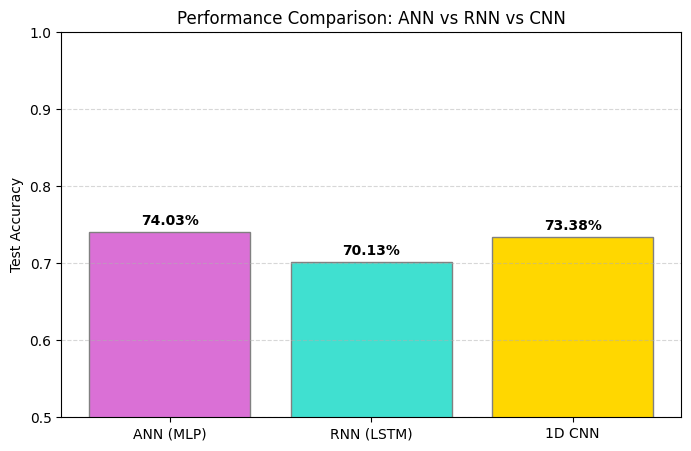

In [ ]:
# Evaluate and plot performance comparisons
loss_ann, acc_ann = ann_model.evaluate(X_test_ann, y_test, verbose=0)
loss_rnn, acc_rnn = rnn_model.evaluate(X_test_3d, y_test, verbose=0)
loss_cnn_c, acc_cnn_c = cnn_model_custom.evaluate(X_test_3d, y_test, verbose=0)

models = ['ANN (MLP)', 'RNN (LSTM)', '1D CNN']
accuracies = [acc_ann, acc_rnn, acc_cnn_c]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies, color=['orchid', 'turquoise', 'gold'], edgecolor='grey')
plt.title('Performance Comparison: ANN vs RNN vs CNN')
plt.ylabel('Test Accuracy')
plt.ylim(0.5, 1.0)
for i, val in enumerate(accuracies):
    plt.text(i, val + 0.01, f"{val*100:.2f}%", ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()